# Детекция отходов на конвейере

Нужно найти каждый объект на изображении и определить один из 15 классов. Формат результата: одна строка на файл, все обнаруженные объекты в поле `bbox` как `[category_id, confidence, x_left, y_top, width, height]`.

План работы: **изучить данные → подготовить разметку → оценить скорость → обучить базовую модель → выгрузить результат → проверить улучшения → выгрузить финальный результат **.

Тетрадка лежит **в корне новой папки** вместе с `train.csv`, `test.csv`, `requirements.txt` и папкой `images/` с JPEG. `sample_submission.csv` содержит образец результата для выгрузки.

### Окружение

Создайте `venv`,  установите совместимую CUDA-сборку PyTorch и зависимости из существующего `requirements.txt`.

```powershell
py -3.13 -m venv .venv
.venv\Scripts\python.exe -m pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128
.venv\Scripts\python.exe -m pip install -r requirements.txt
```

Запуск обучения и предсказания закрыт переключателями; при обычном **Run All** долгие этапы не стартуют.

In [1]:
import ast
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import ultralytics
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image

In [ ]:
PROJECT_DIR = Path.cwd().resolve()  # тетрадка и датасеты лежат в этой папке
IMAGES_DIR = PROJECT_DIR / "images"
RUNS_DIR = PROJECT_DIR / "runs"

RUN_PREPARE = True
RUN_BENCHMARK = True
RUN_TRAIN_S = True
RUN_VALIDATE_S = True
RUN_VALIDATE_S_1280 = True
RUN_FINETUNE_S = True
RUN_VALIDATE_FINETUNED_S = True
RUN_TRAIN_M = True
RUN_VALIDATE_M = True
RUN_PREDICT_S = True
RUN_PREDICT_M = True
RUN_VALIDATE_WBF = True
RUN_SUBMISSION = True

S_BASE_WEIGHTS = RUNS_DIR / "yolo11s_960_50ep" / "weights" / "best_weighted.pt"
S_FINETUNED_WEIGHTS = RUNS_DIR / "yolo11s_960_finetune_100ep" / "weights" / "best_weighted.pt"
# После сравнения валидации можно выбрать S_FINETUNED_WEIGHTS.
S_WEIGHTS = S_BASE_WEIGHTS
M_WEIGHTS = RUNS_DIR / "yolo11m_960_100ep" / "weights" / "best_weighted.pt"
S_CSV = PROJECT_DIR / "submission_s_tta.csv"
M_CSV = PROJECT_DIR / "submission_m_tta.csv"
FINAL_CSV = PROJECT_DIR / "submission_wbf.csv"

# После сравнения на validation впишите один выбранный порог WBF.
SELECTED_WBF_IOU = 0.65

print("Папка проекта:", PROJECT_DIR)
print("Python:", sys.version.split()[0], "| torch:", torch.__version__)
print("Ultralytics:", ultralytics.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "недоступен")

Папка проекта: E:\pets\garbage
Python: 3.13.14 | torch: 2.11.0+cu128
Ultralytics: 8.4.164
GPU: NVIDIA GeForce RTX 4070 SUPER


## 1. Данные: что предсказываем

`train.csv` содержит по строке на каждый размеченный объект: координаты `[x_left, y_top, width, height]` в пикселях и класс `category_id` от 1 до 15. У кадра без объектов поля рамки и класса пустые. Проверяем число файлов, пустые кадры, баланс классов и несколько изображений до преобразования разметки.

In [40]:
train = pd.read_csv(PROJECT_DIR / "train.csv")
test = pd.read_csv(PROJECT_DIR / "test.csv")
sample = pd.read_csv(PROJECT_DIR / "sample_submission.csv")
assert train.file_name.notna().all() and test.file_name.is_unique

In [41]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 32265 entries, 0 to 32264
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   file_name    32265 non-null  str    
 1   bbox         32148 non-null  str    
 2   category_id  32148 non-null  float64
dtypes: float64(1), str(2)
memory usage: 756.3 KB


In [42]:
train.head(7)

,file_name,bbox,category_id
0,000001.jpg,"[840.0, 0.0, 176.0, 124.0]",4.0
1,000001.jpg,"[612.0, 306.0, 383.0, 397.0]",2.0
2,000001.jpg,"[990.92, 551.0, 105.00000000000011, 186.0]",4.0
3,000002.jpg,"[1000.0, 614.0, 98.0, 178.0]",4.0
4,000002.jpg,"[605.0, 358.0, 402.0, 409.0]",2.0
5,000002.jpg,"[838.0, 0.0, 164.0, 184.0]",4.0
6,000004.jpg,"[1002.0, 728.0, 91.0, 178.0]",4.0


In [43]:
train[train.category_id.isna()].head(7)

,file_name,bbox,category_id
1904,000593.jpg,NaN,NaN
1905,000594.jpg,NaN,NaN
1906,000596.jpg,NaN,NaN
4685,001514.jpg,NaN,NaN
4686,001515.jpg,NaN,NaN
4687,001517.jpg,NaN,NaN
4688,001518.jpg,NaN,NaN


In [44]:
test.info()

<class 'pandas.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   file_name  2999 non-null   str  
dtypes: str(1)
memory usage: 23.6 KB


In [45]:
test.head(7)

,file_name
0,000003.jpg
1,000006.jpg
2,000013.jpg
3,000016.jpg
4,000019.jpg
5,000022.jpg
6,000025.jpg


In [46]:
sample.info()

<class 'pandas.DataFrame'>
RangeIndex: 2999 entries, 0 to 2998
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   file_name  2999 non-null   str  
 1   bbox       2999 non-null   str  
dtypes: str(2)
memory usage: 47.0 KB


In [47]:
sample.head(7)

,file_name,bbox
0,000003.jpg,"[[5.0, 0.64, 536.1, 76.56, 834.52, 890.82], [5..."
1,000006.jpg,"[[4.0, 0.91, 397.68, 3.2, 218.05, 970.42], [4...."
2,000013.jpg,[]
3,000016.jpg,"[[8.0, 0.89, 587.89, 771.75, 636.26, 337.43], ..."
4,000019.jpg,"[[7.0, 0.68, 75.08, 220.41, 982.22, 794.76], [..."
5,000022.jpg,"[[11.0, 0.13, 328.83, 596.54, 932.7, 12.92], [..."
6,000025.jpg,"[[3.0, 0.64, 792.9, 27.65, 664.93, 199.32], [3..."


In [48]:
summary = pd.Series({
    "train images": train.file_name.nunique(),
    "train objects": train.bbox.notna().sum(),
    "empty train images": train.groupby("file_name").bbox.count().eq(0).sum(),
    "test images": len(test),
})
display(summary.to_frame("count"))
display(train.category_id.value_counts(dropna=False).sort_index().rename("objects").to_frame())

,count
train images,6001
train objects,32148
empty train images,117
test images,2999


,objects
category_id,
1.0,4747
2.0,7310
3.0,848
4.0,3780
5.0,909
6.0,495
7.0,2530
8.0,364
9.0,653


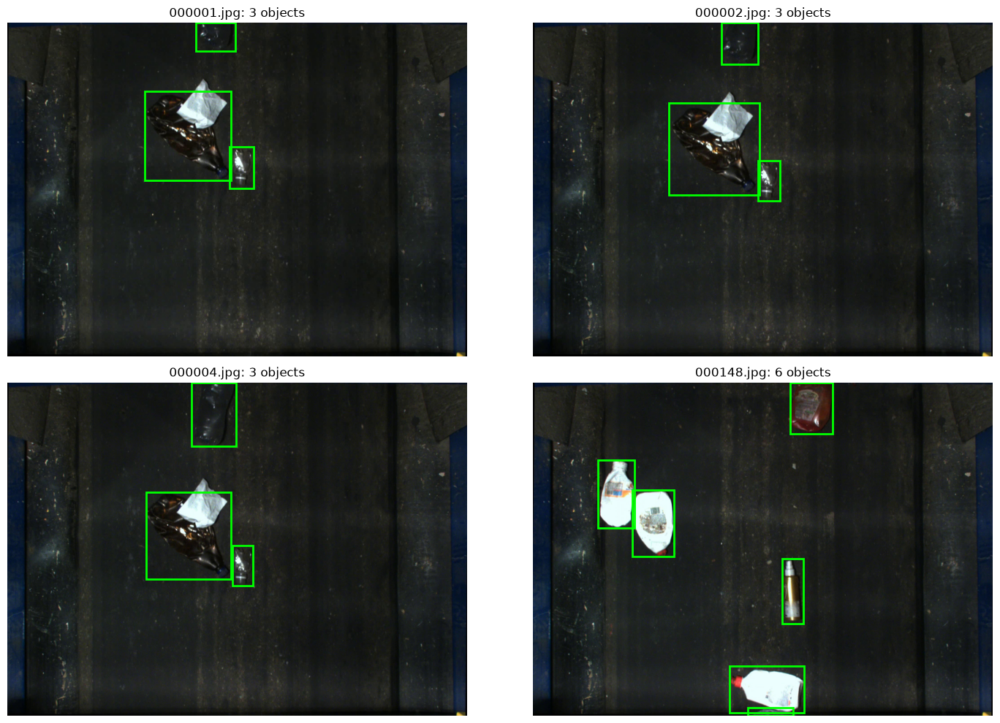

In [49]:
# Несколько выбранных изображений для проверки ориентации координат и пустых кадров.
EXAMPLE_NAMES = train.file_name.drop_duplicates().iloc[[0, 1, 2, 100]].tolist()
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
for ax, name in zip(axes.flat, EXAMPLE_NAMES):
    with Image.open(IMAGES_DIR / name) as image:
        ax.imshow(image)
    rows = train.loc[train.file_name.eq(name)].dropna(subset=["bbox", "category_id"])
    for row in rows.itertuples():
        x, y, w, h = ast.literal_eval(row.bbox)
        ax.add_patch(Rectangle((x, y), w, h, fill=False, edgecolor="lime", linewidth=2))
    ax.set_title(f"{name}: {len(rows)} objects")
    ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Подготовка данных для YOLO

Стандартный загрузчик Ultralytics читает один TXT на изображение; каждая строка содержит нулевой номер класса и **нормированные** `x_center y_center width height`. Преобразуем исходные пиксельные `xywh` относительно исходной ширины и высоты. Для пустого кадра создаём пустой TXT.

Разбиваем **по именам изображений**, с фиксированным seed 42. Если последовательные кадры показывают одну бутылку, случайный split может давать оптимистичную оценку; данных о видеосессиях или ID объекта в CSV нет.

In [50]:
def write_script(filename: str, source: str) -> Path:
    """Создать независимый Python-скрипт рядом с тетрадкой, не перезаписывая существующий."""
    path = PROJECT_DIR /"scripts" / filename
    if path.exists():
        if path.read_text(encoding="utf-8") != source:
            raise FileExistsError(f"Скрипт уже существует и отличается; проверьте его вручную: {path}")
        print("Уже создан:", path)
    else:
        path.write_text(source, encoding="utf-8")
        print("Создан:", path)
    return path

In [56]:
def run_script(filename: str, *arguments: str) -> None:
    """Запускает скрипт и выводит все сообщения (логи YOLO) в реальном времени."""
    command = [sys.executable, "-u", str(PROJECT_DIR / "scripts" / filename), *map(str, arguments)]
    
    # Запускаем процесс, перенаправляя stdout и stderr в одну трубу
    process = subprocess.Popen(
        command,
        cwd=PROJECT_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1  # Построчное буферирование
    )

    # Читаем вывод в реальном времени строка за строкой
    while True:
        line = process.stdout.readline()
        if not line and process.poll() is not None:
            break
        if line:
            print(line, end="", flush=True)

    # Проверяем код завершения
    return_code = process.poll()
    if return_code != 0:
        raise subprocess.CalledProcessError(return_code, command)

In [52]:
if RUN_PREPARE:
    run_script("prepare_data.py", "--project", PROJECT_DIR, "--images", IMAGES_DIR)
else:
    print("Подготовка отключена: установите RUN_PREPARE = True")

## 3. Метрика и выбор checkpoint

Для каждого класса считаем среднюю точность детекции **AP** по порогам IoU от 0,50 до 0,95. Требуемый итог — среднее по классам с весами по числу объектов класса в validation:

$$\operatorname{weighted\ mAP} = \frac{\sum_{c=1}^{15} n_c\, AP_c^{0.50:0.95}}{\sum_{c=1}^{15} n_c}.$$

Метрика одновременно отражает правильный класс, полноту обнаружения и точность рамок. `metrics.py` рассчитывает её по `metrics.box.ap` и `metrics.nt_per_class`, записывает результат каждой эпохи и сохраняет `best_weighted.pt` при улучшении. Обучение по-прежнему использует встроенную функцию потерь YOLO: метрика служит **для оценки и выбора весов**, градиенты через неё не считаются.


## 4. Первый детектор: скорость, базовое обучение, проверка

Начинаем с `YOLO11s` при `imgsz=960`, `batch=16`: короткий 5-эпоховый прогон оценит время и VRAM. На основе результатов продолжим обучение.

`resume_train.py` — **аварийный** скрипт, он ни в одной ячейке автоматически не вызывается. Если обучение оборвётся после сохранения `last.pt` и `best_weighted.pt`, его можно вручную запустить в терминале с `--run-dir <папка запуска>`; он восстановит историю лучшего результата.

In [58]:
if RUN_BENCHMARK:
    run_script("train.py", "--project", PROJECT_DIR, "--stage", "benchmark")
else:
    print("Короткий замер выключен")

New https://pypi.org/project/ultralytics/8.4.171 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.164  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4070 SUPER, 12282MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\pets\garbage\garbage.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo1

Теперь обучим 50 эпох. Веса выбираются по weighted mAP validation. Каждый долгий вызов находится в собственной ячейке; чтобы его выполнить, сначала включите соответствующий переключатель наверху.

In [62]:
if RUN_TRAIN_S:
    run_script("train.py", "--project", PROJECT_DIR, "--stage", "s")
else:
    print("Обучение YOLO11s выключено")

New https://pypi.org/project/ultralytics/8.4.171 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.164  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4070 SUPER, 12282MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\pets\garbage\garbage.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo

,epoch,weighted_map50_95,map50_95
49,50,0.875299,0.866687


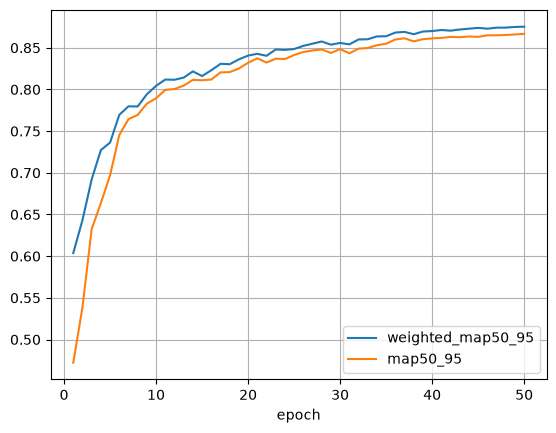

In [63]:
# Просмотр истории после обучения: выбранная эпоха определяется weighted mAP.
history_path = RUNS_DIR / "yolo11s_960_50ep" / "weighted_metrics.csv"
if history_path.exists():
    history = pd.read_csv(history_path)
    display(history.loc[[history.weighted_map50_95.idxmax()]])
    history.plot(x="epoch", y=["weighted_map50_95", "map50_95"], grid=True)
    plt.show()
else:
    print("Сначала завершите обучение YOLO11s")

### Проверяем на отложенных кадрах

`evaluate.py` вызывает `YOLO.val()` и дополнительно выводит weighted mAP. Сначала проверим размер 960 без TTA. Затем при желании проверим 1280 **на тех же весах** в отдельной ячейке: это только эксперимент с размером при предсказании и ничего не доказывает про модель, заново обученную при 1280.

In [65]:
if RUN_VALIDATE_S:
    run_script("evaluate.py", "--project", PROJECT_DIR,
               "--weights", S_BASE_WEIGHTS, "--imgsz", "960")
else:
    print("Проверка YOLO11s при 960 выключена")

Ultralytics 8.4.164  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4070 SUPER, 12282MiB)
YOLO11s summary (fused): 100 layers, 9,418,605 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 106.122.5 MB/s, size: 476.2 KB)

val: Scanning E:\pets\garbage\labels.cache... 1201 images, 18 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1201/1201 335.8Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 1/301 1.1it/s 0.3s<4:21
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 2/301 3.7it/s 0.4s<1:22
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1% ──────────── 4/301 5.7it/s 0.6s<52.4s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1% ──────────── 6/301 7.0it/s 0.8s<41.9s
                 Class     Images  Instances      Box(P          R      mAP50 

In [66]:
if RUN_VALIDATE_S_1280:
    run_script("evaluate.py", "--project", PROJECT_DIR,
               "--weights", S_BASE_WEIGHTS, "--imgsz", "1280")
else:
    print("Проверка YOLO11s при 1280 выключена")

Ultralytics 8.4.164  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4070 SUPER, 12282MiB)
YOLO11s summary (fused): 100 layers, 9,418,605 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 3934.61245.3 MB/s, size: 528.8 KB)

val: Scanning E:\pets\garbage\labels.cache... 1201 images, 18 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1201/1201 359.8Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 1/301 1.3it/s 0.2s<3:44
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 2/301 3.9it/s 0.3s<1:18
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 3/301 5.7it/s 0.4s<52.7s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1% ──────────── 5/301 7.0it/s 0.6s<42.3s
                 Class     Images  Instances      Box(P          R      mAP

## 5. Продолжать ли обучение `s`?

По истории эпох и validation решаем, есть ли смысл продолжить. Следующий опыт стартует **из `best_weighted.pt` базового запуска**, уменьшает learning rate и снова выбирает лучшую эпоху по той же метрике. После него проверяем обычное предсказание и TTA на одинаковых весах. Если дообучение окажется полезным, присвойте наверху `S_WEIGHTS = S_FINETUNED_WEIGHTS`, затем повторно выполните ячейку настроек. По умолчанию `S_WEIGHTS` указывает на базовую модель.

In [68]:
if RUN_FINETUNE_S:
    run_script("train.py", "--project", PROJECT_DIR, "--stage", "s-finetune")
else:
    print("Дообучение YOLO11s выключено")

New https://pypi.org/project/ultralytics/8.4.171 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.164  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4070 SUPER, 12282MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\pets\garbage\garbage.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=

CalledProcessError: Command '['e:\\pets\\garbage\\.venv\\Scripts\\python.exe', '-u', 'E:\\pets\\garbage\\scripts\\train.py', '--project', 'E:\\pets\\garbage', '--stage', 's-finetune']' returned non-zero exit status 1.

Тут продолжили обучение через командную строку  
```powershell
.\.venv\Scripts\python.exe .\scripts\resume_train.py --run-dir .\runs\yolo11s_960_finetune_100ep
```

In [69]:
if RUN_VALIDATE_FINETUNED_S:
    run_script("evaluate.py", "--project", PROJECT_DIR,
               "--weights", S_FINETUNED_WEIGHTS, "--imgsz", "960")
    run_script("evaluate.py", "--project", PROJECT_DIR,
               "--weights", S_FINETUNED_WEIGHTS, "--imgsz", "960", "--tta")
else:
    print("Сравнение без TTA и с TTA выключено")

Ultralytics 8.4.164  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4070 SUPER, 12282MiB)
YOLO11s summary (fused): 100 layers, 9,418,605 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access  (ping: 0.00.0 ms, read: 2797.0840.7 MB/s, size: 484.2 KB)

val: Scanning E:\pets\garbage\labels.cache... 1201 images, 18 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1201/1201 296.3Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 1/301 1.1it/s 0.3s<4:24
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 0% ──────────── 3/301 4.3it/s 0.4s<1:10
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 1% ──────────── 5/301 6.6it/s 0.6s<44.8s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 2% ──────────── 7/301 8.3it/s 0.8s<35.3s
                 Class     Images  Instances      Box(P          R      mAP5

"checkpoint": "E:\\pets\\garbage\\runs\\yolo11s_960_finetune_100ep\\weights\\best_weighted.pt",  
  "imgsz": 960,  
  "tta": false,  
  "weighted_map50_95": 0.881842920710924,  
  "map50_95": 0.8714675815180551,  
  "map50": 0.9565441268365908    
  
"checkpoint": "E:\\pets\\garbage\\runs\\yolo11s_960_finetune_100ep\\weights\\best_weighted.pt",  
  "imgsz": 960,  
  "tta": true,  
  "weighted_map50_95": 0.8821009107482781,  
  "map50_95": 0.8735151852735368,  
  "map50": 0.959115632384176,  

Видим рост метрики при использовании ТТА

## 6. Вторая модель: даст ли иной масштаб сети выигрыш?

Обучаем `YOLO11m` на том же split и при том же `imgsz=960`; физический batch уменьшаем до 8 из-за VRAM. Сравниваем взвешенный AP отдельных моделей при одинаковом способе валидации. Даже если одиночная `m` не окажется лучше, её ошибки могут дополнять `s` — это отдельная гипотеза для ансамбля.

In [ ]:
if RUN_TRAIN_M:
    run_script("train.py", "--project", PROJECT_DIR, "--stage", "m")
else:
    print("Обучение YOLO11m выключено")


New https://pypi.org/project/ultralytics/8.4.171 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.164  Python-3.13.14 torch-2.11.0+cu128 CUDA:0 (NVIDIA GeForce RTX 4070 SUPER, 12282MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=0, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=E:\pets\garbage\garbage.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, kobj=1.0, line_width=None, lr0=0.000526, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model

In [ ]:
if RUN_VALIDATE_M:
    run_script("evaluate.py", "--project", PROJECT_DIR,
               "--weights", M_WEIGHTS, "--imgsz", "960", "--tta")
else:
    print("Валидация YOLO11m выключена")

Валидация YOLO11m выключена


## 7. Предсказания на тесте

`predict.py` обрабатывает тест **небольшими порциями на GPU** и сохраняет отдельный CSV для каждой модели. Используем `conf=0.001`, `iou=0.7`, `max_det=300`, размер 960 и TTA. Берём имена и порядок файлов только из `test.csv`. В submission возвращаем исходные номера классов 1–15 и пиксельные `xywh`; у пустого кадра пишем `[]`.

Здесь и в следующем шаге должны использоваться **те же `best_weighted.pt`**, которые оценивали на validation.

In [ ]:
if RUN_PREDICT_S:
    run_script("predict.py", "--project", PROJECT_DIR, "--images", IMAGES_DIR,
               "--weights", S_WEIGHTS, "--output", S_CSV, "--batch", "8", "--tta")
else:
    print("Предсказания YOLO11s выключены")

Предсказания YOLO11s выключены


In [ ]:
if RUN_PREDICT_M:
    run_script("predict.py", "--project", PROJECT_DIR, "--images", IMAGES_DIR,
               "--weights", M_WEIGHTS, "--output", M_CSV, "--batch", "8", "--tta")
else:
    print("Предсказания YOLO11m выключены")

Предсказания YOLO11m выключены


## 8. Проверка ансамбля и выбор порога

WBF объединяет пересекающиеся рамки **одного класса**, учитывая их confidence. Перед объединением переводим пиксельные `xyxy` в диапазон `[0,1]`, а после возвращаем координаты в пикселях. Две модели достаточны для объединения; выигрыш зависит от того, различаются ли их ошибки.

`ensemble.py` один раз получает обе серии предсказаний на validation и оценивает отдельные модели и WBF при нескольких IoU. Для этого этапа TorchMetrics использует одинаковый лимит 100 рамок на кадр у всех вариантов. Сравните показатели, выберите порог и впишите его в `SELECTED_WBF_IOU` наверху. Затем сформируйте тестовый CSV из двух уже сохранённых CSV без повторного инференса.

In [ ]:
if RUN_VALIDATE_WBF:
    run_script("ensemble.py", "--mode", "val", "--project", PROJECT_DIR,
               "--weights-s", S_WEIGHTS, "--weights-m", M_WEIGHTS,
               "--iou", "0.55", "0.65")
else:
    print("Проверка WBF выключена")

Проверка WBF выключена


In [ ]:
if RUN_SUBMISSION:
    if SELECTED_WBF_IOU is None:
        raise ValueError("Сначала выберите SELECTED_WBF_IOU по результатам validation")
    run_script("ensemble.py", "--mode", "submit", "--project", PROJECT_DIR,
               "--images", IMAGES_DIR, "--csv-s", S_CSV, "--csv-m", M_CSV,
               "--output", FINAL_CSV, "--iou", str(SELECTED_WBF_IOU))
else:
    print("Итоговый CSV не создавался")

Итоговый CSV не создавался


## Выводы после запуска

Сюда можно внести полученные значения weighted mAP для базовой `s`, дообученной `s`, `m` и нескольких порогов WBF, а затем итоговый балл соревнования.